In [17]:
import os
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from numpy.typing import NDArray
from scipy.io import loadmat


### Project structure

```text
├── das_data/
│   ├── test/
│   │   ├── 01_background/
│   │   │   ├── 220112_cxm_background_01_single_data_2.mat
│   │   │   ├── 220112_cxm_background_01_single_data_32.mat
│   │   │   ├── 220112_cxm_background_01_single_data_43.mat
│   │   │   └── ...
│   │   ├── 02_dig/
│   │   │   ├── 220104_sys_dig_01_single_data_10.mat
│   │   │   ├── 220104_sys_dig_01_single_data_11.mat
│   │   │   ├── 220104_sys_dig_01_single_data_12.mat
│   │   │   └── ...
│   │   ├── 03_knock/
│   │   │   ├── 220111_cxm_knock_01_single_data_12.mat
│   │   │   ├── 220111_cxm_knock_02_single_data_101.mat
│   │   │   ├── 220111_cxm_knock_02_single_data_16.mat
│   │   │   └── ...
│   │   ├── 04_water/
│   │   │   ├── 220113_jzy_water_02_single_data_11.mat
│   │   │   ├── 220113_jzy_water_02_single_data_29.mat
│   │   │   ├── 220113_jzy_water_03_single_data_1.mat
│   │   │   └── ...
│   │   ├── 05_shake/
│   │   │   ├── 220116_yu_shake_01_single_data_12.mat
│   │   │   ├── 220116_yu_shake_01_single_data_13.mat
│   │   │   ├── 220116_yu_shake_01_single_data_14.mat
│   │   │   └── ...
│   │   ├── 06_walk/
│   │   │   ├── 220117_yzs_walk_02_single_data_65.mat
│   │   │   ├── 220118_cxm_run_07_single_data_18.mat
│   │   │   ├── 220118_cxm_run_07_single_data_30.mat
│   │   │   └── ...
│   │   └── label.txt
│   ├── train/
│   │   ├── 01_background/
│   │   │   ├── 220112_cxm_background_01_single_data_1.mat
│   │   │   ├── 220112_cxm_background_01_single_data_10.mat
│   │   │   ├── 220112_cxm_background_01_single_data_11.mat
│   │   │   └── ...
│   │   ├── 02_dig/
│   │   │   ├── 220104_sys_dig_01_single_data_1.mat
│   │   │   ├── 220104_sys_dig_01_single_data_13.mat
│   │   │   ├── 220104_sys_dig_01_single_data_14.mat
│   │   │   └── ...
│   │   ├── 03_knock/
│   │   │   ├── 220111_cxm_knock_01_single_data_09.mat
│   │   │   ├── 220111_cxm_knock_01_single_data_10.mat
│   │   │   ├── 220111_cxm_knock_01_single_data_11.mat
│   │   │   └── ...
│   │   ├── 04_water/
│   │   │   ├── 220113_jzy_water_01_single_data_16.mat
│   │   │   ├── 220113_jzy_water_01_single_data_20.mat
│   │   │   ├── 220113_jzy_water_01_single_data_23.mat
│   │   │   └── ...
│   │   ├── 05_shake/
│   │   │   ├── 220116_yu_shake_01_single_data_1.mat
│   │   │   ├── 220116_yu_shake_01_single_data_10.mat
│   │   │   ├── 220116_yu_shake_01_single_data_11.mat
│   │   │   └── ...
│   │   ├── 06_walk/
│   │   │   ├── 220117_yzs_run_03_single_data_50.mat
│   │   │   ├── 220117_yzs_walk_02_single_data_63.mat
│   │   │   ├── 220117_yzs_walk_03_single_data_71.mat
│   │   │   └── ...
│   │   └── label.txt
│   └── readme.txt
└── Untitled.ipynb
```

In [2]:
EXPECTED_SHAPE = (10000, 12)
EXPECTED_DTYPE = np.uint16

def parse_mat(path: Path) -> NDArray[np.uint16] | None:
    if not path.exists():
        print(f'File {path} not found.')
        return None

    try:
        mat_dict: dict[str, Any] = loadmat(path)
    except Exception as e:
        print(f'Error reading {path}: {e}')
        return

    matrix = mat_dict['data']
    if matrix.shape != EXPECTED_SHAPE or matrix.dtype != EXPECTED_DTYPE:
        print(f'Skipping {rel_path}: Invalid shape {matrix.shape} or dtype {matrix.dtype}')
        return

    return matrix

# Test
walk_single_sample_path = Path('das_data/train/06_walk/220117_yzs_run_03_single_data_50.mat')
walk_single_sample = parse_mat(walk_single_sample_path)
walk_single_sample

array([[8039, 8220, 8049, ..., 8511, 8143, 8291],
       [8021, 8218, 8016, ..., 8487, 8099, 8261],
       [8024, 8191, 8066, ..., 8484, 8123, 8273],
       ...,
       [8010, 8197, 8227, ..., 8329, 8082, 8213],
       [8017, 8232, 8255, ..., 8299, 8110, 8205],
       [8019, 8231, 8247, ..., 8326, 8092, 8251]],
      shape=(10000, 12), dtype=uint16)

In [3]:
def read_data(data_dir: Path) -> pd.DataFrame:
    data_list = []

    labels_file = data_dir / 'label.txt'
    
    with open(labels_file, encoding='utf-8') as f:
        for i, line in enumerate(f):
            line = line.strip()
            if not line:
                continue

            file_path_str, label_str = line.rsplit(maxsplit=1)
            label = int(label_str)
    
            # Convert Linux-style paths from label.txt to OS-independent paths
            # Removing leading slash to ensure Path treats it as a relative path
            rel_path = data_dir / Path(file_path_str.lstrip('/'))
    
            matrix = parse_mat(rel_path)

            if matrix is None:
                continue

            data_list.append(
                {
                    'dir': rel_path.parent.name,
                    'filename': rel_path.name,
                    'label': label,
                    'data': matrix,
                }
            )

    df = pd.DataFrame(data_list)
    print(f'Successfully loaded rows: {len(df)}')

    return df

In [4]:
train_data_dir = Path('das_data/train/')
train_df = read_data(train_data_dir)
train_df

Successfully loaded rows: 12335


,dir,filename,label,data
0,01_background,220112_cxm_background_01_single_data_1.mat,0,"[[8379, 8333, 8528, 8434, 8095, 8004, 8039, 79..."
1,01_background,220112_cxm_background_01_single_data_10.mat,0,"[[8124, 8613, 9142, 9084, 8212, 7944, 7932, 78..."
2,01_background,220112_cxm_background_01_single_data_11.mat,0,"[[8284, 8545, 8669, 8769, 8110, 7988, 7899, 79..."
3,01_background,220112_cxm_background_01_single_data_12.mat,0,"[[8506, 8381, 8179, 8254, 7994, 8007, 7954, 79..."
4,01_background,220112_cxm_background_01_single_data_13.mat,0,"[[8356, 8195, 8068, 8157, 7981, 8021, 7993, 79..."
...,...,...,...,...
12330,06_walk,220519_walk_slow2_single_data_54.mat,5,"[[8152, 8207, 8154, 8130, 8084, 8413, 10271, 1..."
12331,06_walk,220519_walk_slow2_single_data_6.mat,5,"[[8064, 8063, 8068, 8131, 8135, 8435, 9441, 95..."
12332,06_walk,220519_walk_slow2_single_data_7.mat,5,"[[8091, 8038, 8122, 8176, 8166, 8269, 9040, 91..."
12333,06_walk,220519_walk_slow2_single_data_8.mat,5,"[[8113, 8086, 8173, 8088, 8088, 8195, 8769, 89..."


In [5]:
test_data_dir = Path('das_data/test/')
test_df = read_data(test_data_dir)
test_df

Error reading das_data/test/01_background/220112_cxm_background_01_single_data_2.mat: Mat file appears to be truncated
Successfully loaded rows: 3083


,dir,filename,label,data
0,01_background,220112_cxm_background_01_single_data_32.mat,0,"[[8861, 9091, 8997, 8533, 7998, 7995, 8039, 80..."
1,01_background,220112_cxm_background_01_single_data_43.mat,0,"[[8551, 8448, 8367, 8265, 7916, 7880, 7934, 80..."
2,01_background,220112_cxm_background_01_single_data_44.mat,0,"[[8359, 8397, 8365, 8367, 7908, 7912, 7895, 79..."
3,01_background,220112_cxm_background_01_single_data_5.mat,0,"[[8242, 8300, 8277, 8306, 8026, 8123, 7928, 79..."
4,01_background,220112_cxm_background_01_single_data_51.mat,0,"[[8509, 8489, 8576, 8550, 8044, 8009, 8016, 80..."
...,...,...,...,...
3078,06_walk,220519_walk_slow2_single_data_10.mat,5,"[[8083, 8127, 8111, 8139, 8241, 8599, 9840, 97..."
3079,06_walk,220519_walk_slow2_single_data_16.mat,5,"[[8106, 8087, 8103, 8068, 8107, 8270, 9228, 93..."
3080,06_walk,220519_walk_slow2_single_data_18.mat,5,"[[8084, 8089, 8221, 8129, 8143, 8534, 9320, 95..."
3081,06_walk,220519_walk_slow2_single_data_21.mat,5,"[[8053, 8093, 8125, 8246, 8250, 8404, 9179, 92..."


In [40]:
dfs: list[pd.DataFrame] = [train_df, test_df]
titles = ['Train', 'Test']

### Distribution of Labels

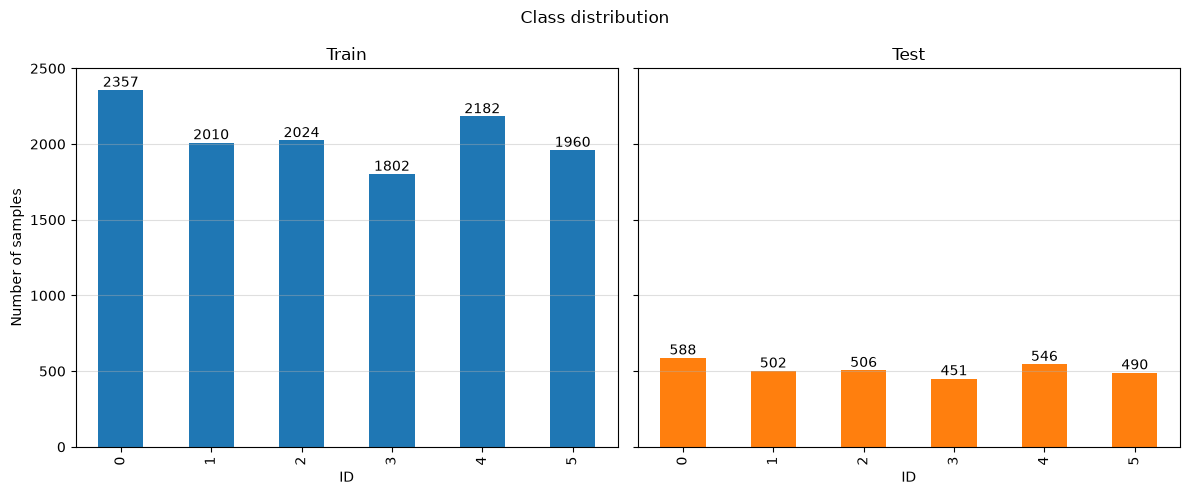

In [16]:
figure, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
figure.suptitle('Class distribution')

for i, df in enumerate(dfs):
    class_counts = df['label'].value_counts().sort_index()
    class_counts.plot(kind='bar', color=f'C{i}', ax=axes[i])
    axes[i].bar_label(axes[i].containers[0])
    axes[i].set_title(titles[i])
    axes[i].set_xlabel('ID')
    axes[i].set_ylabel('Number of samples')
    axes[i].set_yticks(range(0, 3000, 500))
    axes[i].grid(axis='y', alpha=0.4)

plt.tight_layout()
plt.show()


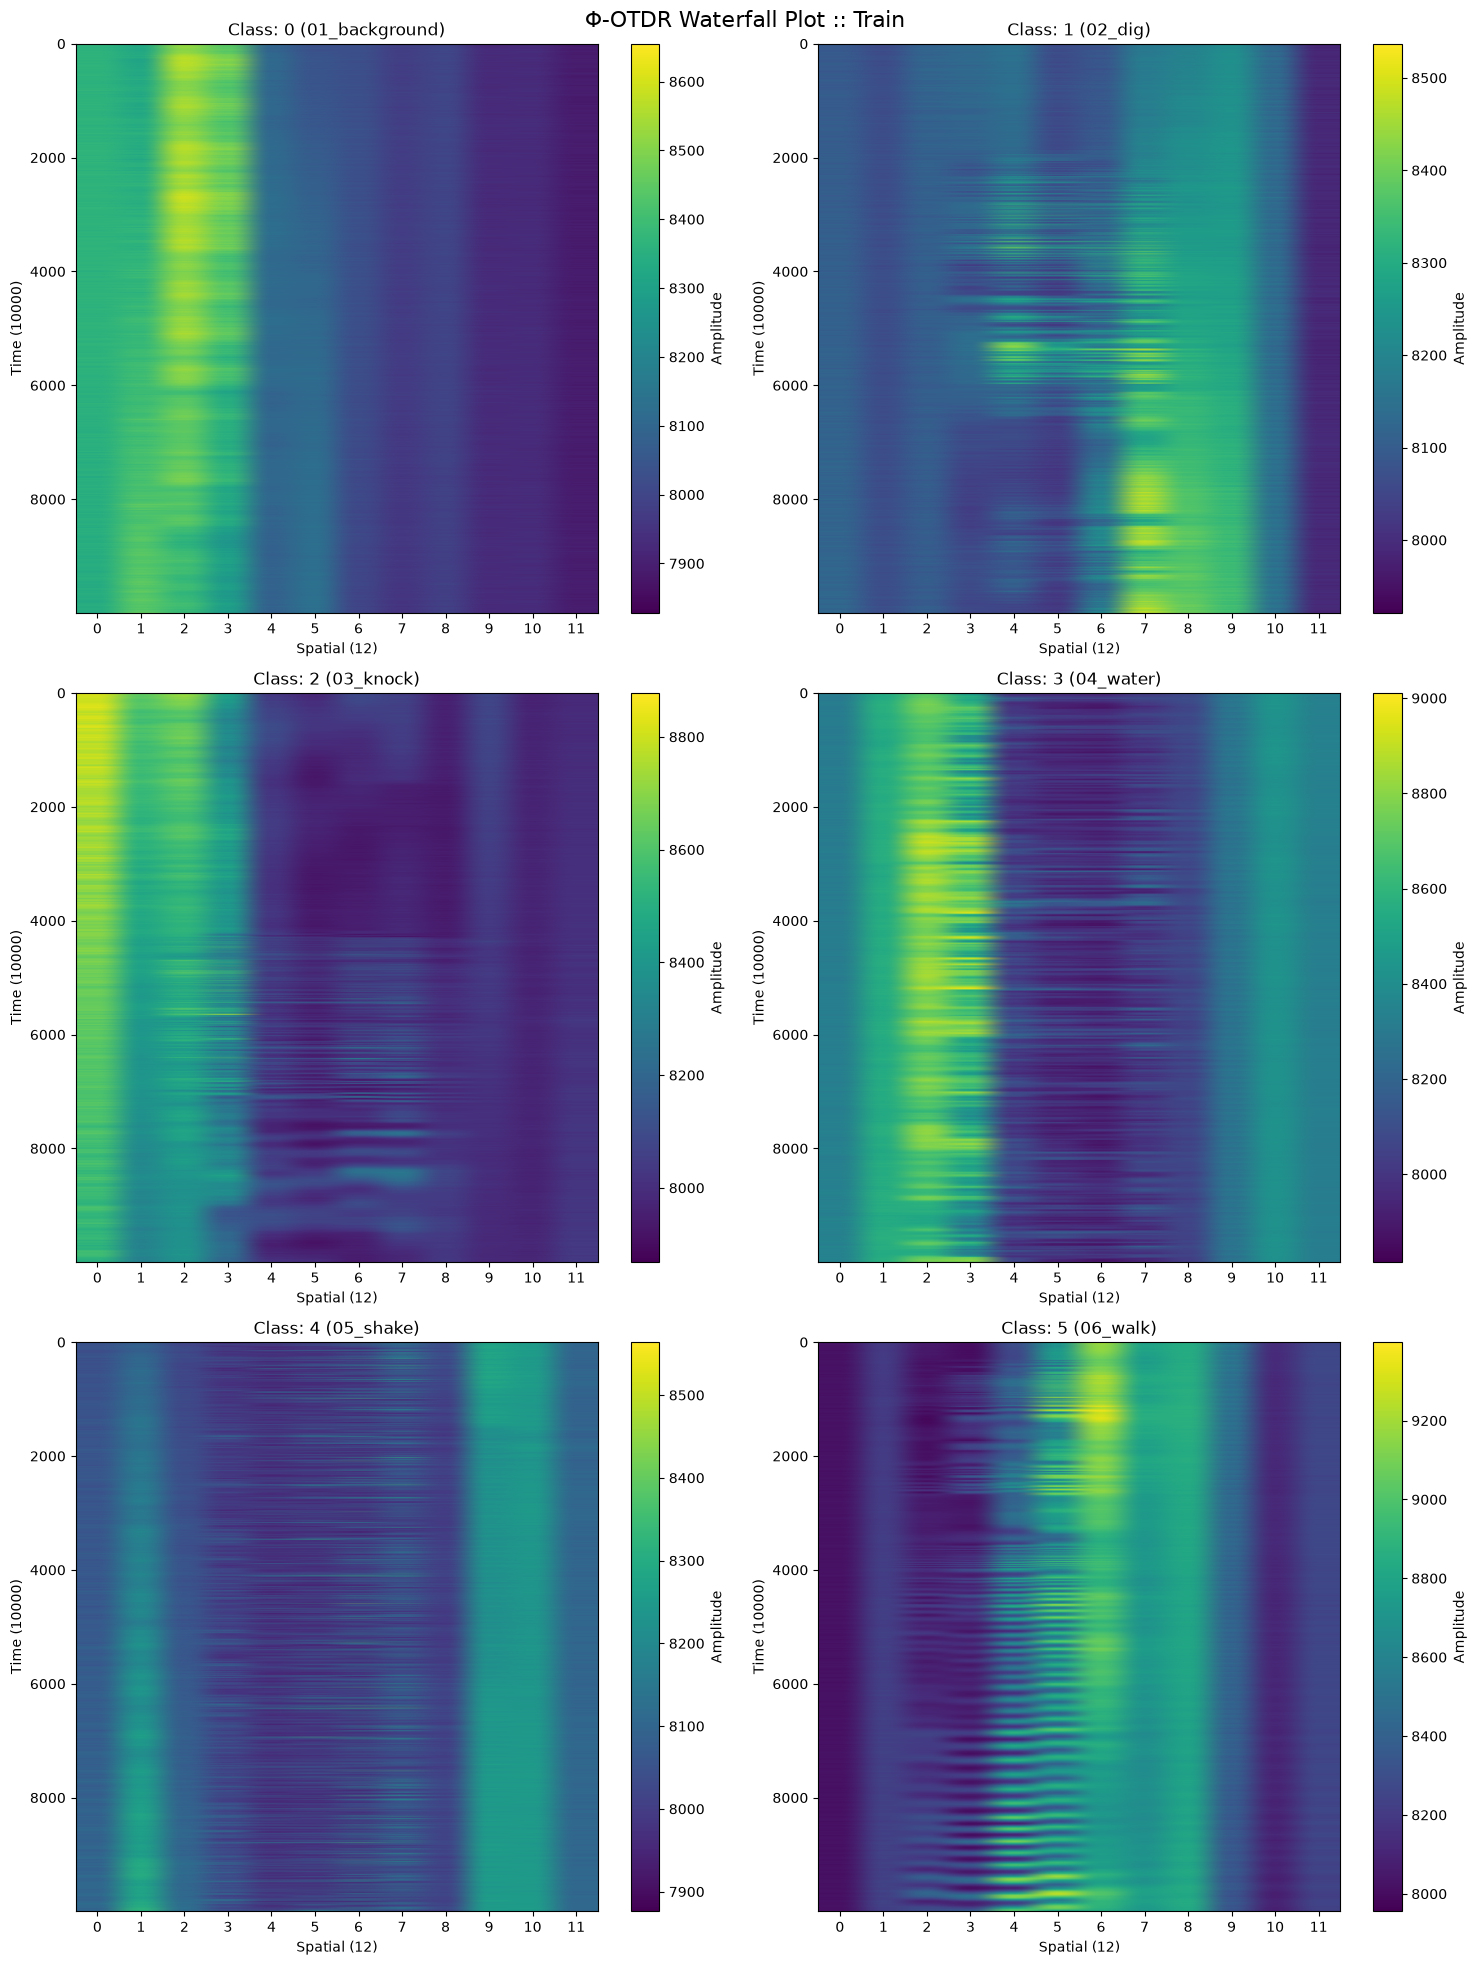

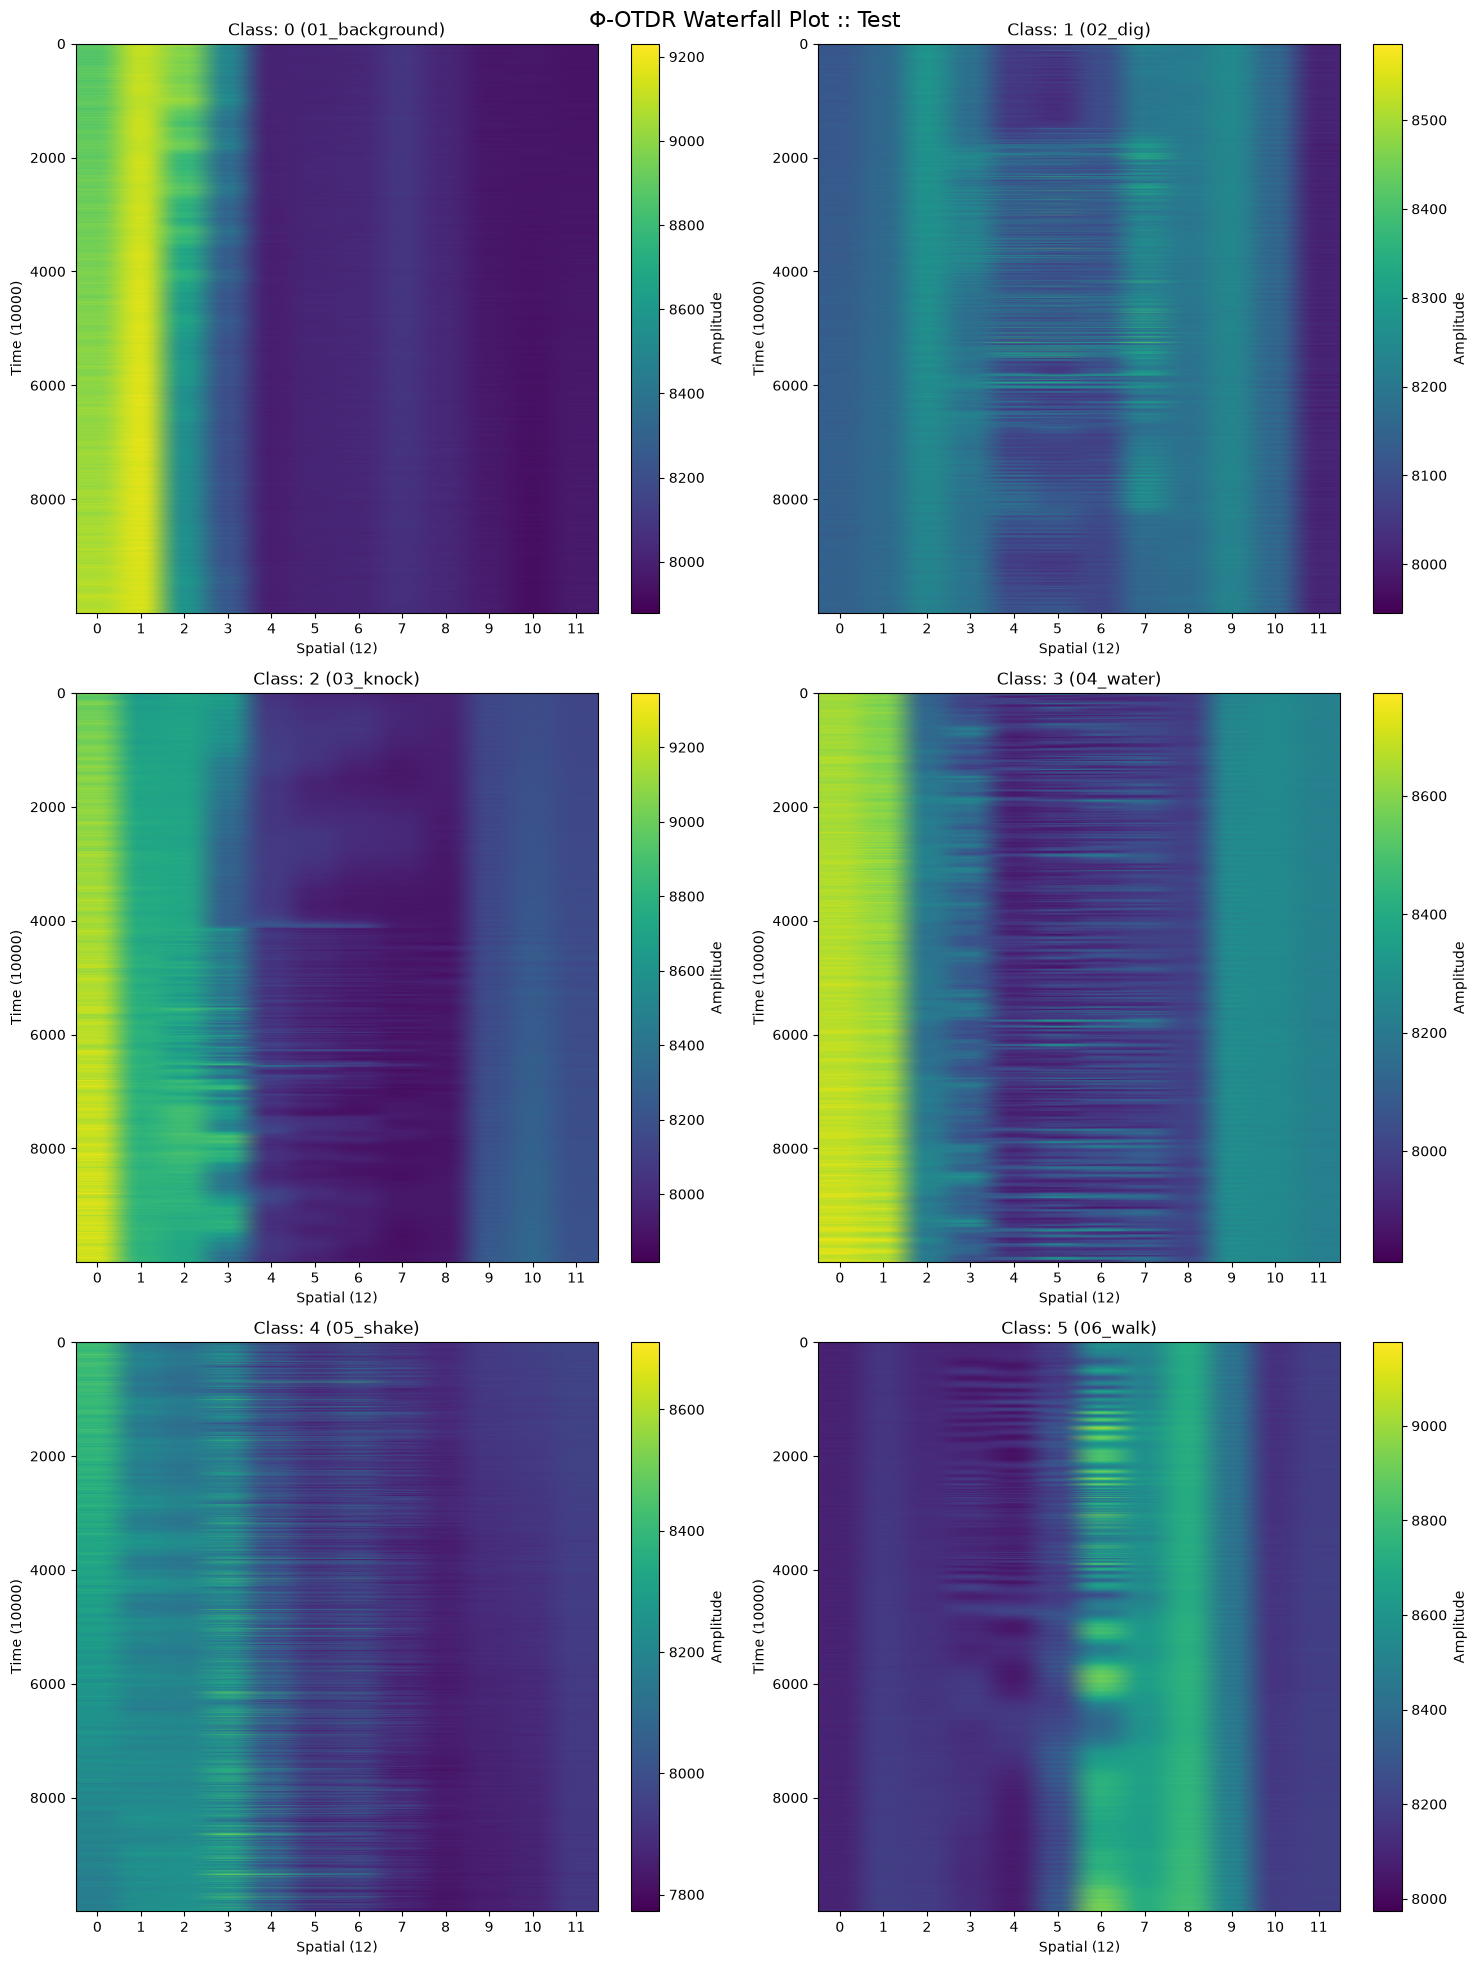

In [41]:
for i, df in enumerate(dfs):
    unique_samples = df.groupby('label').head(1).reset_index(drop=True)
    
    figure, axes = plt.subplots(3, 2, figsize=(15, 20))
    figure.suptitle(f'Φ-OTDR Waterfall Plot :: {titles[i]}', fontsize=16)
    
    for i, ax in enumerate(axes.flatten()):
        sample_data = unique_samples.iloc[i]['data']
        sample_label = unique_samples.iloc[i]['label']
        sample_name = unique_samples.iloc[i]['dir']
    
        im = ax.imshow(sample_data, aspect='auto', cmap='viridis')
    
        ax.set_title(f'Class: {sample_label} ({sample_name})')
        ax.set_xlabel('Spatial (12)')
        ax.set_xticks(range(12))
        ax.set_ylabel('Time (10000)')
    
        figure.colorbar(im, ax=ax, label='Amplitude')
    
    plt.tight_layout()
    plt.show()

### Basic descriptive statistics

In [31]:
for df in dfs:
    df['min'] = df['data'].apply(np.min)
    df['mean'] = df['data'].apply(np.mean)
    df['median'] = df['data'].apply(np.median)
    df['max'] = df['data'].apply(np.max)
    df['std'] = df['data'].apply(np.std)
    display(df)

,dir,filename,label,data,min,max,mean,median,std
0,01_background,220112_cxm_background_01_single_data_1.mat,0,"[[8379, 8333, 8528, 8434, 8095, 8004, 8039, 79...",7828,8655,8129.824067,8046.0,208.146272
1,01_background,220112_cxm_background_01_single_data_10.mat,0,"[[8124, 8613, 9142, 9084, 8212, 7944, 7932, 78...",7839,9214,8196.116317,7956.0,392.129485
2,01_background,220112_cxm_background_01_single_data_11.mat,0,"[[8284, 8545, 8669, 8769, 8110, 7988, 7899, 79...",7858,8832,8118.660200,7979.0,242.546524
3,01_background,220112_cxm_background_01_single_data_12.mat,0,"[[8506, 8381, 8179, 8254, 7994, 8007, 7954, 79...",7885,8571,8071.931783,8006.0,149.969256
4,01_background,220112_cxm_background_01_single_data_13.mat,0,"[[8356, 8195, 8068, 8157, 7981, 8021, 7993, 79...",7919,8491,8069.832833,8010.0,122.067889
...,...,...,...,...,...,...,...,...,...
12330,06_walk,220519_walk_slow2_single_data_54.mat,5,"[[8152, 8207, 8154, 8130, 8084, 8413, 10271, 1...",7902,11206,8694.959917,8178.0,793.719101
12331,06_walk,220519_walk_slow2_single_data_6.mat,5,"[[8064, 8063, 8068, 8131, 8135, 8435, 9441, 95...",7952,9877,8453.910333,8137.0,493.530408
12332,06_walk,220519_walk_slow2_single_data_7.mat,5,"[[8091, 8038, 8122, 8176, 8166, 8269, 9040, 91...",7951,9659,8478.573083,8156.0,513.484320
12333,06_walk,220519_walk_slow2_single_data_8.mat,5,"[[8113, 8086, 8173, 8088, 8088, 8195, 8769, 89...",7942,9944,8457.511750,8167.0,479.995104


,dir,filename,label,data,min,max,mean,median,std
0,01_background,220112_cxm_background_01_single_data_32.mat,0,"[[8861, 9091, 8997, 8533, 7998, 7995, 8039, 80...",7878,9231,8259.965225,8030.0,414.967226
1,01_background,220112_cxm_background_01_single_data_43.mat,0,"[[8551, 8448, 8367, 8265, 7916, 7880, 7934, 80...",7831,8620,8109.023908,7996.0,214.322652
2,01_background,220112_cxm_background_01_single_data_44.mat,0,"[[8359, 8397, 8365, 8367, 7908, 7912, 7895, 79...",7783,8471,8044.350967,7919.0,205.964691
3,01_background,220112_cxm_background_01_single_data_5.mat,0,"[[8242, 8300, 8277, 8306, 8026, 8123, 7928, 79...",7869,8532,8095.585550,7991.0,182.011041
4,01_background,220112_cxm_background_01_single_data_51.mat,0,"[[8509, 8489, 8576, 8550, 8044, 8009, 8016, 80...",7931,8655,8185.030058,8038.0,233.971838
...,...,...,...,...,...,...,...,...,...
3078,06_walk,220519_walk_slow2_single_data_10.mat,5,"[[8083, 8127, 8111, 8139, 8241, 8599, 9840, 97...",7942,10453,8499.653292,8137.0,556.499667
3079,06_walk,220519_walk_slow2_single_data_16.mat,5,"[[8106, 8087, 8103, 8068, 8107, 8270, 9228, 93...",7957,10199,8502.320083,8191.0,521.003181
3080,06_walk,220519_walk_slow2_single_data_18.mat,5,"[[8084, 8089, 8221, 8129, 8143, 8534, 9320, 95...",7955,10280,8495.021200,8207.0,519.503795
3081,06_walk,220519_walk_slow2_single_data_21.mat,5,"[[8053, 8093, 8125, 8246, 8250, 8404, 9179, 92...",7948,10580,8466.154608,8194.0,490.834628


In [33]:
for df in dfs:
    class_comparison = df.groupby('label')[['min', 'mean', 'median', 'max', 'std']].mean()
    display(class_comparison)

,min,mean,median,max,std
label,,,,,
0,7914.481544,8145.131029,8098.155494,8522.177344,149.239439
1,7905.385075,8131.636888,8085.798507,8756.797512,146.202440
2,7898.676383,8127.333501,8065.703557,8749.841403,157.368659
3,7878.612653,8208.732722,8126.569645,9064.502775,233.829993
4,7907.933547,8132.426364,8102.885426,8761.596700,128.749271
5,7915.761735,8234.133212,8143.530612,9160.243367,227.294578


,min,mean,median,max,std
label,,,,,
0,7913.625850,8147.315202,8099.528912,8527.195578,151.882286
1,7906.151394,8126.765634,8086.331673,8754.904382,138.098536
2,7896.363636,8121.487100,8063.268775,8748.541502,152.939855
3,7875.325942,8200.072419,8120.076497,9026.733925,228.320088
4,7905.959707,8127.347600,8095.786630,8752.540293,129.557268
5,7916.538776,8213.934594,8138.877551,9066.155102,204.678913


In [38]:
global_min = df['min'].min()
global_min

np.uint16(7713)

In [35]:
global_max = df['max'].max()
global_max

np.uint16(14736)